In [1]:
import datetime
import numpy as np
import scipy as sp
import scipy.io
import gsw
import matplotlib.pyplot as plt
import run_wave_speeds

def datenum_to_datetime(datenum):
    if np.isnan(datenum):
        return np.datetime64('NaT')
    days = datenum % 1
    return (datetime.datetime.fromordinal(int(datenum))
            + datetime.timedelta(days=days)
            - datetime.timedelta(days=366))


In [2]:
fmat=sp.io.loadmat('mooring_data_byevent_v1p3.mat')
datetimes = [datenum_to_datetime(fmat['Arrivals'][0][i]) for i in range(len(fmat['Arrivals'][0]))]

In [3]:
#Compute density from temperature and depth measurements using GSW toolbox of TEOS-10 
#As in McSweeney et al. 2020, use a constant salinity of 33.43PSU
depth = fmat['H'][:,:,:]-fmat['H'][:,-1,:][:,np.newaxis,:]
pressure = gsw.p_from_z(depth, lat=35)
abs_salt = gsw.SA_from_SP(33.43, pressure,lon=-127, lat=35)
cons_temp = gsw.CT_from_t(abs_salt, fmat['T'][:,:,:], pressure)
density = gsw.rho(abs_salt, cons_temp, pressure)

In [4]:
# Mode-1 SI filter: background-subtracted, rotated velocity; no temporal smoothing.
# A pass requires mean integral ratio >0.9 and raw eastward top-bottom >-0.03 m/s.
# mode1 contains 1 (pass), 0 (fail), or NaN (missing data/undefined rotation).
from scipy.integrate import cumulative_trapezoid, trapezoid

bore_slots = np.asarray(fmat['idxArray']).ravel().astype(int)
n_bores = int(bore_slots.max())
n_arrivals = fmat['U'].shape[0]
if n_arrivals % n_bores:
    raise ValueError('Expected complete mooring blocks of bore slots.')
n_moorings = n_arrivals // n_bores
if not np.array_equal(bore_slots, np.tile(np.arange(1, n_bores+1), n_moorings)):
    raise ValueError('Expected mooring-major ordering with bore slots 1..n_bores.')

minutes = np.asarray(fmat['minArray']).ravel()
if minutes[90] != 0 or not np.allclose(np.diff(minutes), 1):
    raise ValueError('Expected one-minute data with arrival at index 90.')
pre = slice(60, 90)
post = slice(90, 121)
shape = (n_moorings, n_bores)
mode1 = np.full(shape, np.nan)
mode1_ratio = np.full(shape, np.nan)
topbottom = np.full(shape, np.nan)
rotation_angle = np.full(shape, np.nan)  # degrees
rotation_depth = np.full(shape, np.nan)  # metres above bed

for Jidx in range(n_moorings):
    J = Jidx * n_bores
    for i in range(n_bores):
        if np.isnan(np.mean(fmat['U'][J+i, :, :])):
            continue
        z = fmat['H'][J+i, :, 0]
        rho = density[J+i, :, :]
        u = fmat['U'][J+i, :, :]
        v = fmat['V'][J+i, :, :]
        if not (np.isfinite(z).all() and np.isfinite(rho).all()
                and np.isfinite(u).all() and np.isfinite(v).all()):
            continue
        o = np.argsort(z)
        z, rho, u, v = z[o], rho[o], u[o], v[o]
        H = z[-1]
        b_tot = -9.8 / 1027 * (rho - np.max(np.mean(rho[:, pre], axis=1)))
        b_profile = np.mean(b_tot[:, pre], axis=1)
        u_profile = np.mean(u[:, pre], axis=1)
        v_profile = np.mean(v[:, pre], axis=1)
        x_new = np.linspace(np.min(b_tot), np.max(b_tot), 25)
        u_bspace = np.column_stack([
            np.interp(x_new, b_tot[:, t], u[:, t]) for t in range(u.shape[1])])
        v_bspace = np.column_stack([
            np.interp(x_new, b_tot[:, t], v[:, t]) for t in range(v.shape[1])])
        u_bspace -= np.interp(x_new, b_profile, u_profile)[:, None]
        v_bspace -= np.interp(x_new, b_profile, v_profile)[:, None]
        u_depth = np.column_stack([
            np.interp(b_tot[:, t], x_new, u_bspace[:, t]) for t in range(u.shape[1])])
        v_depth = np.column_stack([
            np.interp(b_tot[:, t], x_new, v_bspace[:, t]) for t in range(v.shape[1])])

        # Estimate the angle over minutes 0–29, matching the original rotation.
        rotation_post = slice(90, 120)
        zidx = np.argmax(np.mean(u_depth[:, rotation_post], axis=1))
        zl = max(0, zidx - 3)
        band = slice(zl, zidx + 3)
        mean_u = np.mean(u_depth[band, rotation_post])
        mean_v = np.mean(v_depth[band, rotation_post])
        # Ratio of means
        if np.isclose(mean_u, 0.0, rtol=0.0, atol=1e-12):
            continue  # undefined/unstable angle: leave comparison flags as NaN
        theta = np.arctan(mean_v / mean_u)
        rotation_angle[Jidx, i] = np.degrees(theta)
        rotation_depth[Jidx, i] = z[zidx]
        ua = np.cos(theta) * u_depth + np.sin(theta) * v_depth
        uas = ua[:, post]  # no temporal smoothing

        # SI integral-ratio test on the background-subtracted, rotated velocity.
        zz = np.concatenate([[0.0], z])
        uu = np.vstack([uas[:1], uas])
        Ubar = trapezoid(uu, zz, axis=0) / H
        phi = cumulative_trapezoid(uu - Ubar, zz, axis=0, initial=0)
        ratio = np.mean(np.abs(trapezoid(phi, zz, axis=0)) /
                        np.maximum(trapezoid(np.abs(phi), zz, axis=0), 1e-12))
        # Use exactly the original direction diagnostic (endpoints, minutes 0–29).
        raw_profile = np.mean(fmat['U'][J+i, :, rotation_post], axis=1)
        dU = raw_profile[-1] - raw_profile[0]
        mode1_ratio[Jidx, i] = ratio
        topbottom[Jidx, i] = dU
        mode1[Jidx, i] = ratio > 0.9 and dU > -0.03
    print('.', end='', flush=True)


print(f'\nMode-1 onshore arrivals: {np.count_nonzero(mode1 == 1)}')
print(f'Evaluated arrivals: {np.isfinite(mode1).sum()}')
print(f'Skipped (missing data or undefined rotation): {np.isnan(mode1).sum()}')
is_mode1 = mode1 == 1  # Boolean mask for selecting arrivals later


..........................................
Mode-1 onshore arrivals: 1838
Evaluated arrivals: 2914
Skipped (missing data or undefined rotation): 3974


In [5]:
from scipy.interpolate import interp1d
from scipy.integrate import cumulative_trapezoid, trapezoid
from scipy.signal import savgol_filter


def analyse(Hm, Tm, Um, Vm, arrival_datenum=None, mooring_name=None):
    """All inputs are (depth, time).

    Inputs have minute -90 origin (arrival index 90).
    Hm is height above bed, in metres, as in fmat['H'].
    arrival_datenum is the MATLAB arrival datenum; mooring_name may be a
    string or the nested MATLAB array from fmat. Both are optional.
    Returns diagnostics plus datetime and mooring; theta is in radians. Energies are normalized
    by rho0*gprime*H**2. Missing inputs produce NaN for dependent outputs.
    """
    names = ('H', 'A', 'C', 'lam', 'S', 'U', 'etaB', 'etaGC', 'APE', 'KE',
             'max_depression', 'KE_v', 'buoyancy_max_displacement',
             'theta', 'DeltaGC')
    out = dict.fromkeys(names, np.nan)
    # Preserve metadata even when measurements are missing.
    if arrival_datenum is None:
        out['datetime'] = np.datetime64('NaT')
    else:
        arrival_values = np.asarray(arrival_datenum).reshape(-1)
        if arrival_values.size != 1:
            raise ValueError('arrival_datenum must contain one MATLAB datenum.')
        out['datetime'] = datenum_to_datetime(float(arrival_values[0]))
    name = mooring_name
    while isinstance(name, np.ndarray) and name.size == 1:
        name = name.item()
    if isinstance(name, np.ndarray):
        name = ''.join(str(part) for part in name.reshape(-1))
    if isinstance(name, bytes):
        name = name.decode()
    out['mooring'] = None if name is None else str(name).strip()

    Hm, Tm, Um, Vm = (np.asarray(x, dtype=float) for x in (Hm, Tm, Um, Vm))
    if (Hm.ndim != 2 or Tm.ndim != 2 or Um.shape != Tm.shape
            or Vm.shape != Tm.shape or Hm.shape[0] != Tm.shape[0]
            or Hm.shape[1] not in (1, Tm.shape[1])
            or Tm.shape[1] < 120 or Tm.shape[0] < 2):
        raise ValueError('Expected compatible (depth, time) arrays with >=120 time samples.')
    pre, post = slice(60, 90), slice(90, 150)
    z = Hm[:, 0]
    if not np.isfinite(z).all() or np.any(np.diff(z) <= 0) or z[-1] <= 0:
        return out
    out['H'] = float(z[-1])  # total water depth
    if not np.isfinite(Tm).all():
        return out

    # Depth/pressure/GSW density calculation; no background sorting.
    depth_local = Hm - Hm[-1:, :]
    pressure_local = gsw.p_from_z(depth_local, lat=35)
    salt = gsw.SA_from_SP(33.43, pressure_local, lon=-127, lat=35)
    temp = gsw.CT_from_t(salt, Tm, pressure_local)
    rho = gsw.rho(salt, temp, pressure_local)
    if not np.isfinite(rho).all():
        return out
    rho_ref = np.max(np.mean(rho[:, pre], axis=1))
    b_tot = -9.8 / 1027 * (rho - rho_ref)
    b_profile = np.mean(b_tot[:, pre], axis=1)
    A = np.max(b_profile)
    H = z[-1]
    if not np.isfinite(A) or A <= 0:
        return out
    out['A'] = float(A)

    # Normalized tanh fit: A is fixed; fit C and lam to db/dz.
    grad_true = np.gradient(b_profile, z)
    best_rmse = np.inf
    for C in z:
        for lam in np.linspace(2, 22, 21):
            shape = np.tanh((z-C)/lam) - np.tanh((z[0]-C)/lam)
            fit = A * shape / np.max(shape)
            rmse = np.sqrt(np.sum((grad_true - np.gradient(fit, z))**2) / len(z))
            if rmse < best_rmse:
                best_rmse = rmse
                out['C'], out['lam'] = float(C), float(lam)

    # Intrusion buoyancy estimate: average bins at b/A >= 0.999.
    mask = b_tot / A >= 0.999
    count = np.sum(mask, axis=0)
    intrusion_b = np.full(b_tot.shape[1], A)
    np.divide(np.sum(b_tot * mask, axis=0), count,
              out=intrusion_b, where=count > 0)
    out['S'] = float(np.mean(b_profile[-1] / intrusion_b[post]))

    # Isopycnal displacement: invert background buoyancy, then clip to the column.
    get_z_star = interp1d(b_profile, z, bounds_error=False, fill_value='extrapolate')
    z_star = np.clip(get_z_star(b_tot), 0, H)
    eta0 = z[:, None] - z_star
    out['etaB'] = float(np.max(np.abs(np.mean(eta0[:, post], axis=1))))
    gc_idx = np.abs(np.mean(b_tot[:, post], axis=1) - b_profile[-1]).argmin()
    out['etaGC'] = float(abs(np.mean(eta0[gc_idx, post])))
    out['max_depression'] = float(abs(np.min(eta0[:, post])))
    # Use a matched depth/time pair within the post-arrival window.
    peak_idx = np.unravel_index(np.argmax(np.abs(eta0[:, post])), eta0[:, post].shape)
    out['buoyancy_max_displacement'] = float(b_tot[:, post][peak_idx])
    
    # Track interior background isopycnals plus the surface isopycnal.
    b_levels = np.r_[b_profile[1:-1], b_profile[-1]]
    z_ref_levels = np.clip(get_z_star(b_levels), 0, H)

    z_isopycnal = np.column_stack([
        np.interp(b_levels, b_tot[:, t], z)
        for t in range(Tm.shape[1])
    ])

    # Positive displacement means depression.
    eta_isopycnal = z_ref_levels[:, None] - z_isopycnal

    # Smooth over time, then find the maximum within the post-arrival window.
    eta_window = savgol_filter(eta_isopycnal, 31, 2, axis=1)
    out['etaB'] = float(np.max(eta_window[:-1, post]))
    out['etaGC'] = float(np.max(eta_window[-1, post]))

    # APE
    phi_values = cumulative_trapezoid(b_profile, z, initial=0)
    get_phi = interp1d(z, phi_values, bounds_error=False, fill_value='extrapolate')
    ape_local = b_tot * eta0 - (get_phi(z[:, None]) - get_phi(z_star))
    total_ape = trapezoid(ape_local, z, axis=0) / (A * H**2)
    out['APE'] = float(abs(np.mean(total_ape[post])))
    if out['etaB'] > 0 and out['S'] > 0:
        out['DeltaGC'] = float((out['etaGC']/out['etaB'])**2
                               * (1-out['S'])/out['S'])
    elif np.isfinite(out['etaB']) and np.isfinite(out['S']):
        # Fallback for non-positive amplitude or S.
        out['DeltaGC'] = 0.0

    # Missing velocity leaves temperature-derived quantities intact.
    if not np.isfinite(Um).all() or not np.isfinite(Vm).all():
        return out
    u_profile, v_profile = (np.mean(x[:, pre], axis=1) for x in (Um, Vm))
    b_grid = np.linspace(np.min(b_tot), np.max(b_tot), 25)
    u_bspace = np.column_stack([
        np.interp(b_grid, b_tot[:, t], Um[:, t]) for t in range(Tm.shape[1])])
    v_bspace = np.column_stack([
        np.interp(b_grid, b_tot[:, t], Vm[:, t]) for t in range(Tm.shape[1])])
    u_bspace -= np.interp(b_grid, b_profile, u_profile)[:, None]
    v_bspace -= np.interp(b_grid, b_profile, v_profile)[:, None]
    u_depth = np.column_stack([
        np.interp(b_tot[:, t], b_grid, u_bspace[:, t]) for t in range(Tm.shape[1])])
    v_depth = np.column_stack([
        np.interp(b_tot[:, t], b_grid, v_bspace[:, t]) for t in range(Tm.shape[1])])

    zidx = np.argmax(np.mean(u_depth[:, post], axis=1))
    band = slice(max(0, zidx-3), zidx+3)
    mean_u = np.mean(u_depth[band, post])
    mean_v = np.mean(v_depth[band, post])
    if np.isclose(mean_u, 0, rtol=0, atol=1e-12):
        return out
    theta = np.arctan(mean_v / mean_u)
    out['theta'] = float(theta)
    u_rot = np.cos(theta)*u_depth + np.sin(theta)*v_depth
    v_rot = np.sin(theta)*u_depth - np.cos(theta)*v_depth
    out['U'] = float(np.max(savgol_filter(np.mean(u_rot[band], axis=0), 31, 2)[post]))
    out['KE'] = float(0.5*np.mean(trapezoid(
        u_rot[:, post]**2/(A*H), z/H, axis=0)))
    out['KE_v'] = float(0.5*np.mean(trapezoid(
        v_rot[:, post]**2/(A*H), z/H, axis=0)))
    return out


In [6]:
#Test example
Jidx, i = 23, 70  # mooring index, bore index
event = Jidx * 164 + i

result = analyse(
    fmat['H'][event],
    fmat['T'][event],
    fmat['U'][event],
    fmat['V'][event],
    arrival_datenum=fmat['Arrivals'][0][event],
    mooring_name=fmat['moorArray'][0][event],
)

result

{'H': 39.976805947474126,
 'A': 0.005321182515047934,
 'C': 31.648304708417015,
 'lam': 22.0,
 'S': 0.7493423526094379,
 'U': 0.3732182691523482,
 'etaB': 23.372290409961728,
 'etaGC': 24.06153575125302,
 'APE': 0.10222010304033209,
 'KE': 0.09854927255264445,
 'max_depression': 24.61827492373564,
 'KE_v': 0.01960767098311907,
 'buoyancy_max_displacement': 0.005256235202263112,
 'theta': -0.7212537118336446,
 'DeltaGC': 0.35452332850721946,
 'datetime': datetime.datetime(2017, 10, 10, 16, 1, 0, 3),
 'mooring': 'ps40M'}

In [7]:
#Pre-arrival background, using the density already calculated above.
z_metres = np.asarray(fmat['H'][event, :, 0], dtype=float)
rho_background = np.mean(density[event, :, 60:90], axis=1)
if not np.isfinite(z_metres).all() or not np.isfinite(rho_background).all():
    raise ValueError('Selected arrival has missing height or pre-arrival density data.')
if np.any(np.diff(z_metres) <= 0) or z_metres[-1] <= 0:
    raise ValueError('Selected arrival requires increasing height above bed and positive depth.')
H_selected = z_metres[-1]
b_background = -9.8/1027 * (rho_background - np.max(rho_background))
gprime_selected = np.max(b_background)
if gprime_selected <= 0:
    raise ValueError('Selected arrival has no positive background buoyancy contrast.')
N2_dimensional = np.gradient(b_background, z_metres)

# Solver inputs are nondimensional: z/H and N2_dimensional*H/gprime.
z_data = z_metres / H_selected
N2_data = N2_dimensional * H_selected / gprime_selected
if (z_data.ndim != 1 or z_data.size < 4 or N2_data.shape != z_data.shape
        or not np.isfinite(N2_data).all() or np.any(N2_data < 0)
        or z_data[0] < 0 or z_data[-1] > 1 + 1e-8):
    raise ValueError('Expected heights within [0,H] and finite nonnegative background N2; no clipping is applied.')

#Uniform solver grid and endpoint continuation.
z_djl = np.linspace(0, 1, max(101, len(z_data)))
N2_djl = np.interp(z_djl, z_data, N2_data)
speed_scale = np.sqrt(gprime_selected * H_selected)

In [10]:
#An example of a DJL equation solve.
result_smooth = None  # do not retain a previous arrival if both branches fail
djl_plot_event = event
print(f'Mooring {Jidx}, bore {i}, arrival {datetimes[event]}')
print(f'H={H_selected:.3f} m, gprime={gprime_selected:.6g} m/s^2')
c0, alpha_kdv = run_wave_speeds.calc_c0(z_djl, N2_djl, z_djl[1] - z_djl[0])
verbose = True #print details from DJL solver
print(f'Dimensionless c0={c0:.6g}, alpha_KdV={alpha_kdv:.6g}; c0={c0*speed_scale:.6g} m/s')
if N2_djl[-1]<0.5:
    try:
        print('looking for standard conjugate state')
        result_smooth = run_wave_speeds.no_core_djl_solver(
            N2_djl, z_djl, verbose=verbose, residual_tol=5e-3
        )
        print(f'cDJL={result_smooth["c"]*speed_scale:.6g} m/s, '
            f'max displacement={result_smooth["max_abs_eta"]*H_selected:.6g} m')
    except:
        print('None found, looking for trapped core')
        try: 
            result_smooth = run_wave_speeds.smooth_core_djl_solver(
            N2_djl, z_djl, verbose=verbose, residual_tol=5e-3
            )
            print(f'cDJL={result_smooth["c"]*speed_scale:.6g} m/s, '
                f'max displacement={result_smooth["max_abs_eta"]*H_selected:.6g} m')
        except:
            print('No solution with trapped core found')
if N2_djl[-1]>=0.5:
    try:
        print('looking for trapped core solution')
        result_smooth = run_wave_speeds.smooth_core_djl_solver(
            N2_djl, z_djl, verbose=verbose, residual_tol=5e-3
        )
        print(f'cDJL={result_smooth["c"]*speed_scale:.6g} m/s, '
            f'max displacement={result_smooth["max_abs_eta"]*H_selected:.6g} m')
    except:
        print('None found, looking for standard conjugate state')
        try: 
            result_smooth = run_wave_speeds.no_core_djl_solver(
            N2_djl, z_djl, verbose=verbose, residual_tol=5e-3
            )
            print(f'cDJL={result_smooth["c"]*speed_scale:.6g} m/s, '
                f'max displacement={result_smooth["max_abs_eta"]*H_selected:.6g} m')
        except:
            print('No solution without trapped core found')
    

Mooring 23, bore 70, arrival 2017-10-10 16:01:00.000003
H=39.977 m, gprime=0.00532118 m/s^2
Dimensionless c0=0.324746, alpha_KdV=-0.0488531; c0=0.149779 m/s
looking for trapped core solution
smooth_core: generating 25 coarse seed shots
Local solve 1: alpha=-1.025, c=0.36855953, h=0.846318458
  alpha=-1.025, c=0.36855953, h=0.846318458: boundary=-2.904e-02, slope=-1.934e-10, momentum=-2.599e-02
  alpha=-1.0251025, c=0.36855953, h=0.846318458: boundary=-2.906e-02, slope=+8.892e-05, momentum=-2.604e-02
  alpha=-1.025, c=0.368596386, h=0.846318458: boundary=-2.914e-02, slope=-1.760e-04, momentum=-2.609e-02
  alpha=-1.025, c=0.36855953, h=0.84640309: boundary=-2.904e-02, slope=+1.512e-04, momentum=-2.599e-02
  alpha=-1.00424368, c=0.362309819, h=0.839694107: boundary=-9.825e-03, slope=-2.807e-04, momentum=+1.766e-03
  alpha=-1.0043441, c=0.362309819, h=0.839694107: boundary=-9.839e-03, slope=-1.919e-04, momentum=+1.718e-03
  alpha=-1.00424368, c=0.36234605, h=0.839694107: boundary=-9.920e-0

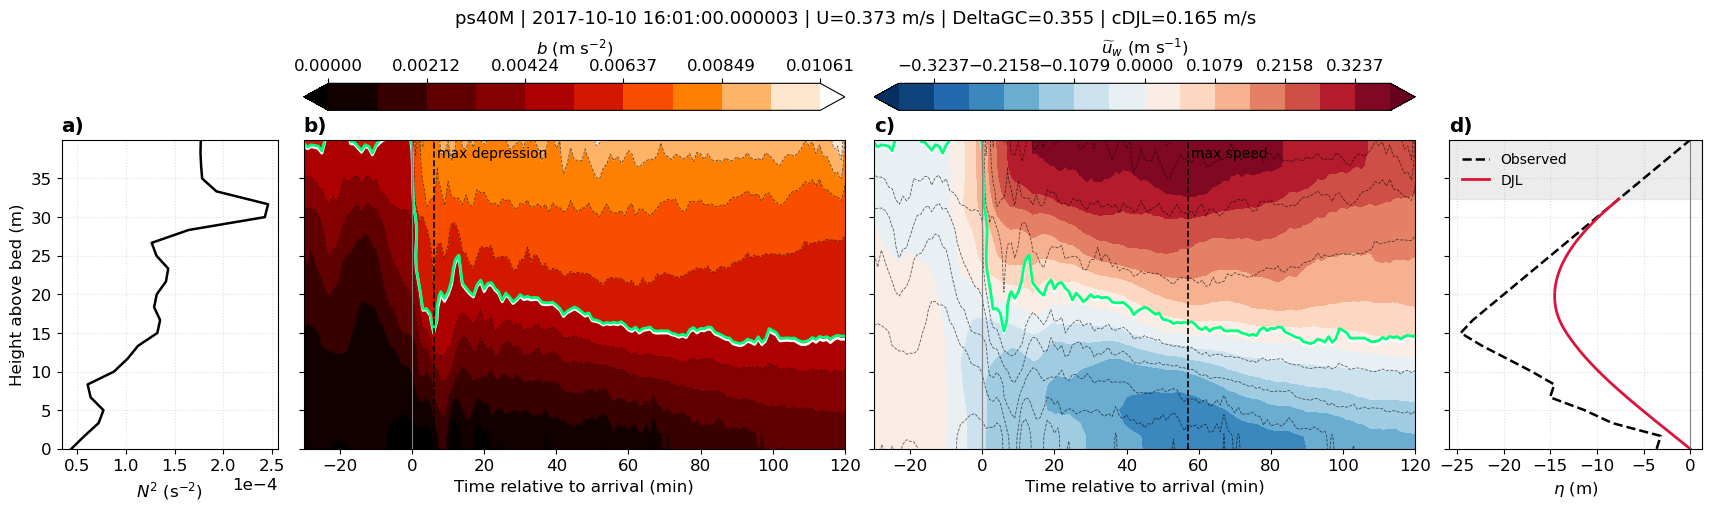

In [12]:
# Supplementary-style diagnostic plot for the selected test arrival.
# Uses the existing diagnostics and DJL solution; does not run a solver.
from scipy.interpolate import interp1d
from scipy.signal import savgol_filter

def plot_arrival(fmat, density, event, stats, djl_result=None, time_limits=(-30, 120)):
    """Four-panel arrival plot; all displayed heights/displacements are in metres."""
    z = np.asarray(fmat['H'][event, :, 0], dtype=float)
    t = np.asarray(fmat['minArray']).ravel()
    rho = density[event]
    pre, post = slice(60, 90), slice(90, 150)
    H = z[-1]
    b = -9.8/1027 * (rho - np.max(np.mean(rho[:, pre], axis=1)))
    b_background = np.mean(b[:, pre], axis=1)
    N2 = np.gradient(b_background, z)
    z_ref = np.clip(interp1d(b_background, z, bounds_error=False,
                            fill_value='extrapolate')(b), 0, H)
    eta = z[:, None] - z_ref
    # Same instantaneous maximum depression used in the saturation diagnostic.
    peak_z, peak_t = np.unravel_index(np.argmin(eta[:, post]), eta[:, post].shape)
    peak_t += post.start
    peak_b = b[peak_z, peak_t]

    # Reconstruct the original isopycnal background subtraction and rotation.
    b_grid = np.linspace(np.min(b), np.max(b), 25)
    anomalies = []
    for key in ('U', 'V'):
        velocity = fmat[key][event]
        background = np.mean(velocity[:, pre], axis=1)
        on_b_grid = np.column_stack([
            np.interp(b_grid, b[:, k], velocity[:, k]) for k in range(len(t))])
        on_b_grid -= np.interp(b_grid, b_background, background)[:, None]
        anomalies.append(np.column_stack([
            np.interp(b[:, k], b_grid, on_b_grid[:, k]) for k in range(len(t))]))
    u, v = anomalies
    theta = stats['theta']
    along = np.cos(theta)*u + np.sin(theta)*v
    along_filtered = savgol_filter(along, 31, 2, axis=1)
    zidx = np.argmax(np.mean(u[:, post], axis=1))
    band = slice(max(0, zidx-3), zidx+3)
    band_speed = np.mean(along_filtered[band], axis=0)
    speed_t = post.start + np.argmax(band_speed[post])
    visible = (t >= time_limits[0]) & (t <= time_limits[1])
    bmax = max(float(np.max(b[:, visible])), float(np.max(b_background)), 1e-8)
    umax = max(float(np.nanmax(np.abs(along_filtered[:, visible]))), 1e-6)
    contour_levels = np.linspace(0, bmax, 11)

    with plt.rc_context({'font.size': 12, 'text.usetex': False}):
        fig, axes = plt.subplots(1, 4, figsize=(17, 5), sharey=True,
                                 layout='constrained',
                                 gridspec_kw={'width_ratios': [1.2, 3, 3, 1.4]})
        ax_N2, ax_b, ax_u, ax_eta = axes
        ax_N2.plot(N2, z, color='black', lw=1.8)
        ax_N2.set(xlabel=r'$N^2$ (s$^{-2}$)', ylabel='Height above bed (m)', ylim=(0, H))
        ax_N2.ticklabel_format(axis='x', style='sci', scilimits=(0, 0))
        ax_N2.grid(ls=':', alpha=0.4)

        im_b = ax_b.contourf(t, z, b, levels=contour_levels,
                             extend='both', cmap='gist_heat')
        fig.colorbar(im_b, ax=ax_b, location='top', pad=0.02,
                     label=r'$b$ (m s$^{-2}$)')
        im_u = ax_u.contourf(t, z, along_filtered,
                             levels=np.linspace(-umax, umax, 15),
                             extend='both', cmap='RdBu_r')
        fig.colorbar(im_u, ax=ax_u, location='top', pad=0.02,
                     label=r'$\widetilde{u}_w$ (m s$^{-1}$)')
        for ax in (ax_b, ax_u):
            ax.contour(t, z, b, levels=contour_levels,
                       colors='black', linestyles='--', linewidths=0.6, alpha=0.6)
            if np.min(b) < peak_b < np.max(b):
                ax.contour(t, z, b, levels=[peak_b], colors='white', linewidths=2)
            if np.min(b) < b_background[-1] < np.max(b):
                ax.contour(t, z, b, levels=[b_background[-1]],
                           colors='springgreen', linewidths=2)
            ax.axvline(0, color='grey', lw=0.8)
            ax.set(xlim=time_limits, xlabel='Time relative to arrival (min)')
        for ax, k, label in [(ax_b, peak_t, r'max depression'),
                              (ax_u, speed_t, r'max speed')]:
            ax.axvline(t[k], color='black', ls='--', lw=1.2)
            ax.text(t[k]+1, 0.98, label, transform=ax.get_xaxis_transform(),
                    va='top', fontsize=10)

        ax_eta.plot(eta[:, peak_t], z, 'k--', lw=1.8, label='Observed')
        if djl_result is not None:
            ax_eta.plot(djl_result['eta']*H, djl_result['z_eta']*H,
                         color='crimson', lw=2, label='DJL')
            if djl_result.get('h', 1.0) < 1:
                ax_eta.axhspan(djl_result['h']*H, H, color='grey', alpha=0.15)
        else:
            ax_eta.text(0.05, 0.95, 'No accepted DJL solution',
                        transform=ax_eta.transAxes, va='top', fontsize=10)
        ax_eta.axvline(0, color='grey', lw=0.8)
        ax_eta.set_xlabel(r'$\eta$ (m)')
        ax_eta.grid(ls=':', alpha=0.4)
        ax_eta.legend(frameon=False, fontsize=10)
        for ax, letter in zip(axes, ('a)', 'b)', 'c)', 'd)')):
            ax.set_title(letter, loc='left', fontweight='bold')
        summary = (f"{stats['mooring']} | {stats['datetime']} | "
                   f"U={stats['U']:.3f} m/s | DeltaGC={stats['DeltaGC']:.3f}")
        if djl_result is not None:
            scale = np.sqrt(np.max(b_background)*H)
            summary += f" | cDJL={djl_result['c']*scale:.3f} m/s"
        fig.suptitle(summary, fontsize=13)
    return fig, axes


if djl_plot_event != event:
    raise ValueError('Rerun the DJL example for the currently selected arrival first.')
fig_arrival, axes_arrival = plot_arrival(fmat, density, event, result, result_smooth)
# Optional export:
# fig_arrival.savefig(f'arrival_{Jidx}_{i}.png', dpi=300, bbox_inches='tight')
plt.show()


In [18]:
#Diagnosed bore statistics for all selected mode-1 arrivals. Should take ~2-3 minutes.
selected = is_mode1 

shape = (42, 164)
if np.shape(selected) != shape:
    raise ValueError('Expected a 42 x 164 selection mask.')
numeric_fields = (
    'H', 'A', 'C', 'lam', 'S', 'U',
    'etaB', 'etaGC', 'APE', 'KE', 'max_depression',
    'KE_v', 'buoyancy_max_displacement', 'theta', 'DeltaGC',
)
bore_stats = {name: np.full(shape, np.nan) for name in numeric_fields}
bore_stats['datetime'] = np.full(shape, np.datetime64('NaT'), dtype='datetime64[us]')
bore_stats['mooring'] = np.full(shape, None, dtype=object)

for Jidx in range(42):
    for i in np.flatnonzero(selected[Jidx]):
        event = Jidx * 164 + i
        result = analyse(
            fmat['H'][event], fmat['T'][event],
            fmat['U'][event], fmat['V'][event],
            arrival_datenum=fmat['Arrivals'][0][event],
            mooring_name=fmat['moorArray'][0][event],
        )
        for name in bore_stats:
            bore_stats[name][Jidx, i] = result[name]
    print('.', end='', flush=True)  # one dot per completed mooring

print(f'\nProcessed {np.count_nonzero(selected)} selected arrivals.')
# Example: np.nanmedian(bore_stats['etaB'])


..........................................
Processed 1838 selected arrivals.


In [9]:
np.savez_compressed('bore_stats.npz', **bore_stats)

In [ ]:
#In order to run the DJL solver on the full dataset, it is easiest to first export the required inputs,
#and then run the solve of the full dataset in the background. Export inputs to be used below:

In [123]:
# Export all selected mode-1 arrivals; no DJL solves are run here (this is done separately).
# Same normalization and 101-point grid as the selected-arrival example.
indices = np.argwhere(is_mode1)
n_export = len(indices)
n_grid = max(101, density.shape[1])
z_hat = np.full((n_export, n_grid), np.nan)
N2_hat = np.full((n_export, n_grid), np.nan)
H_export = np.full(n_export, np.nan)
speed_scale_export = np.full(n_export, np.nan)
uniform_z = np.linspace(0, 1, n_grid)

for k, (Jidx_export, i_export) in enumerate(indices):
    event_export = Jidx_export*n_bores + i_export
    z_export = np.asarray(fmat['H'][event_export, :, 0], dtype=float)
    rho_export = np.mean(density[event_export, :, 60:90], axis=1)
    if (not np.isfinite(z_export).all() or not np.isfinite(rho_export).all()
            or np.any(np.diff(z_export) <= 0) or z_export[0] < 0 or z_export[-1] <= 0):
        continue
    b_export = -9.8/1027 * (rho_export - np.max(rho_export))
    gp_export = np.max(b_export)
    if gp_export <= 0:
        continue
    N2_export = np.gradient(b_export, z_export)
    # New wave_speeds solvers require nonnegative N2; do not silently clip it.
    if not np.isfinite(N2_export).all() or np.any(N2_export < 0):
        continue
    H_export[k] = z_export[-1]
    speed_scale_export[k] = np.sqrt(gp_export*H_export[k])
    z_hat[k] = uniform_z
    N2_hat[k] = np.interp(uniform_z, z_export/H_export[k],
                          N2_export*H_export[k]/gp_export)
    if (k+1) % 100 == 0:
        print('.', end='', flush=True)

# Retain original field names for remote scripts; add the actual dataset shape.
np.savez_compressed(
    'djl_inputs.npz', indices=indices, z_hat=z_hat, N2_hat=N2_hat,
    H=H_export, speed_scale=speed_scale_export,
    grid_shape=np.asarray(is_mode1.shape, dtype=int),
)
n_valid_export = np.count_nonzero(np.isfinite(N2_hat).all(axis=1))
print(f'\nSaved djl_inputs.npz: {n_export} selected arrivals, {n_valid_export} usable profiles.')
print(f'Skipped input profiles (stored as NaN): {n_export-n_valid_export}')
print(f'Mooring/bore grid: {is_mode1.shape}')


.................
Saved djl_inputs.npz: 1838 selected arrivals, 1799 usable profiles.
Skipped input profiles (stored as NaN): 39
Mooring/bore grid: (42, 164)
